# LightGBM versus XGBoost comparison

This notebook compares the completed LightGBM and XGBoost outputs from `3-LightGBM/outputs/` and `4-XGBoost/outputs/`.

The comparison is made on the exact common `zone_id + timestamp` rows. The primary table uses rows where the baseline file marks `scored == 1`, so both algorithms are evaluated on identical observations. Lower MAE, RMSE, CV(RMSE), absolute NMBE, and WAPE are better.

**Models compared:** LightGBM final versus the XGBoost research-preserving reduced model. The reduced XGBoost model retains representative indoor and weather variables while removing only conservative low-value/redundant variables.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name != 'Qn_B':
    ROOT = next(p for p in [ROOT, *ROOT.parents] if p.name == 'Qn_B')
LGB_DIR = ROOT / '3-LightGBM' / 'outputs'
XGB_DIR = ROOT / '4-XGBoost' / 'outputs'
OUT_DIR = XGB_DIR / 'model_comparison'
OUT_DIR.mkdir(parents=True, exist_ok=True)
print('LightGBM outputs:', LGB_DIR)
print('XGBoost outputs:', XGB_DIR)

LightGBM outputs: /Users/wzc/Desktop/SMU/Y3T1/IS4001 Smart Building Analytics/project/git/is4001/Qn_B/3-LightGBM/outputs
XGBoost outputs: /Users/wzc/Desktop/SMU/Y3T1/IS4001 Smart Building Analytics/project/git/is4001/Qn_B/4-XGBoost/outputs


## 1. Load and align predictions

In [2]:
lgb = pd.read_parquet(LGB_DIR / 'test_predictions.parquet')
xgb = pd.read_csv(XGB_DIR / 'final_models' / 'predictions.csv', parse_dates=['timestamp'])
xgb = xgb.loc[xgb['model'].eq('research_preserving')].rename(columns={'prediction': 'XGBoost research-preserving'})
keys = ['zone_id', 'timestamp']
common = lgb.merge(xgb, on=keys, suffixes=('_lgb', '_xgb'), how='inner')
common = common.loc[common['scored'].eq(1)].copy()
print(f'LightGBM prediction rows: {len(lgb):,}')
print(f'XGBoost prediction rows: {len(xgb):,}')
print(f'Common scored rows: {len(common):,}')
print(f'Common timestamp range: {common.timestamp.min()} to {common.timestamp.max()}')
assert np.allclose(common['ac_load_kw_lgb'], common['ac_load_kw_xgb'], equal_nan=True)
assert np.array_equal(common['is_operating_hours_lgb'], common['is_operating_hours_xgb'])
common[['zone_id','timestamp','ac_load_kw_lgb','is_operating_hours_lgb','LGBM final','XGBoost research-preserving']].head()

LightGBM prediction rows: 46,064
XGBoost prediction rows: 50,567
Common scored rows: 46,064
Common timestamp range: 2018-07-08 00:00:00 to 2018-09-30 23:00:00


,zone_id,timestamp,ac_load_kw_lgb,is_operating_hours_lgb,LGBM final,XGBoost research-preserving
0,F2_Z1,2018-07-08 00:00:00,0.0,0,0.001712,0.221011
1,F2_Z1,2018-07-08 01:00:00,0.0,0,0.000386,0.000000
2,F2_Z1,2018-07-08 02:00:00,0.0,0,0.000380,0.000000
3,F2_Z1,2018-07-08 03:00:00,0.0,0,0.000146,0.000000
4,F2_Z1,2018-07-08 04:00:00,0.0,0,0.000000,0.000000


## 2. Metric calculation on identical rows

In [3]:
def metrics(actual, predicted):
    y = pd.to_numeric(actual, errors='coerce').to_numpy(float)
    p = pd.to_numeric(predicted, errors='coerce').to_numpy(float)
    valid = np.isfinite(y) & np.isfinite(p)
    y, p = y[valid], p[valid]
    error = p-y
    mean_y = np.mean(y)
    return {'n': len(y), 'MAE': np.mean(np.abs(error)), 'RMSE': np.sqrt(np.mean(error**2)),
            'CV(RMSE)%': 100*np.sqrt(np.mean(error**2))/mean_y if mean_y else np.nan,
            'NMBE%': 100*np.mean(error)/mean_y if mean_y else np.nan,
            'WAPE%': 100*np.sum(np.abs(error))/np.sum(np.abs(y)) if np.sum(np.abs(y)) else np.nan}

pred_cols = {'LightGBM final':'LGBM final','XGBoost research-preserving':'XGBoost research-preserving'}
rows=[]
for model, col in pred_cols.items():
    for hours, mask in [('all hours', pd.Series(True,index=common.index)),('operating hours', common['is_operating_hours_lgb'].eq(1))]:
        rows.append({'model':model,'hours':hours,**metrics(common.loc[mask,'ac_load_kw_lgb'],common.loc[mask,col])})
comparison=pd.DataFrame(rows)
comparison.to_csv(OUT_DIR/'common_model_metrics.csv',index=False)
display(comparison.round(4))

,model,hours,n,MAE,RMSE,CV(RMSE)%,NMBE%,WAPE%
0,LightGBM final,all hours,46064,0.8014,2.7185,64.2894,-2.3635,18.9531
1,LightGBM final,operating hours,12602,1.6648,2.7221,19.9066,0.6995,12.1749
2,XGBoost research-preserving,all hours,46064,1.0374,2.7946,66.0890,6.2172,24.5337
3,XGBoost research-preserving,operating hours,12602,1.7598,2.7441,20.0681,3.0895,12.8693


## 3. Which model is better?

In [4]:
operating = comparison[comparison['hours'].eq('operating hours')].copy()
metric_names=['MAE','RMSE','CV(RMSE)%','WAPE%']
winners=[]
for metric in metric_names:
    winner=operating.loc[operating[metric].idxmin(),'model']
    winners.append({'metric':metric,'winner':winner,'best_value':operating[metric].min()})
summary=pd.DataFrame(winners)
summary.to_csv(OUT_DIR/'winner_summary.csv',index=False)
display(summary.round(4))
print('\nPrimary decision metric: operating-hours WAPE')
print('Best model:', operating.loc[operating['WAPE%'].idxmin(),'model'])
print('Best WAPE:', f"{operating['WAPE%'].min():.2f}%")

,metric,winner,best_value
0,MAE,LightGBM final,1.6648
1,RMSE,LightGBM final,2.7221
2,CV(RMSE)%,LightGBM final,19.9066
3,WAPE%,LightGBM final,12.1749



Primary decision metric: operating-hours WAPE
Best model: LightGBM final
Best WAPE: 12.17%


## 4. Visual comparison

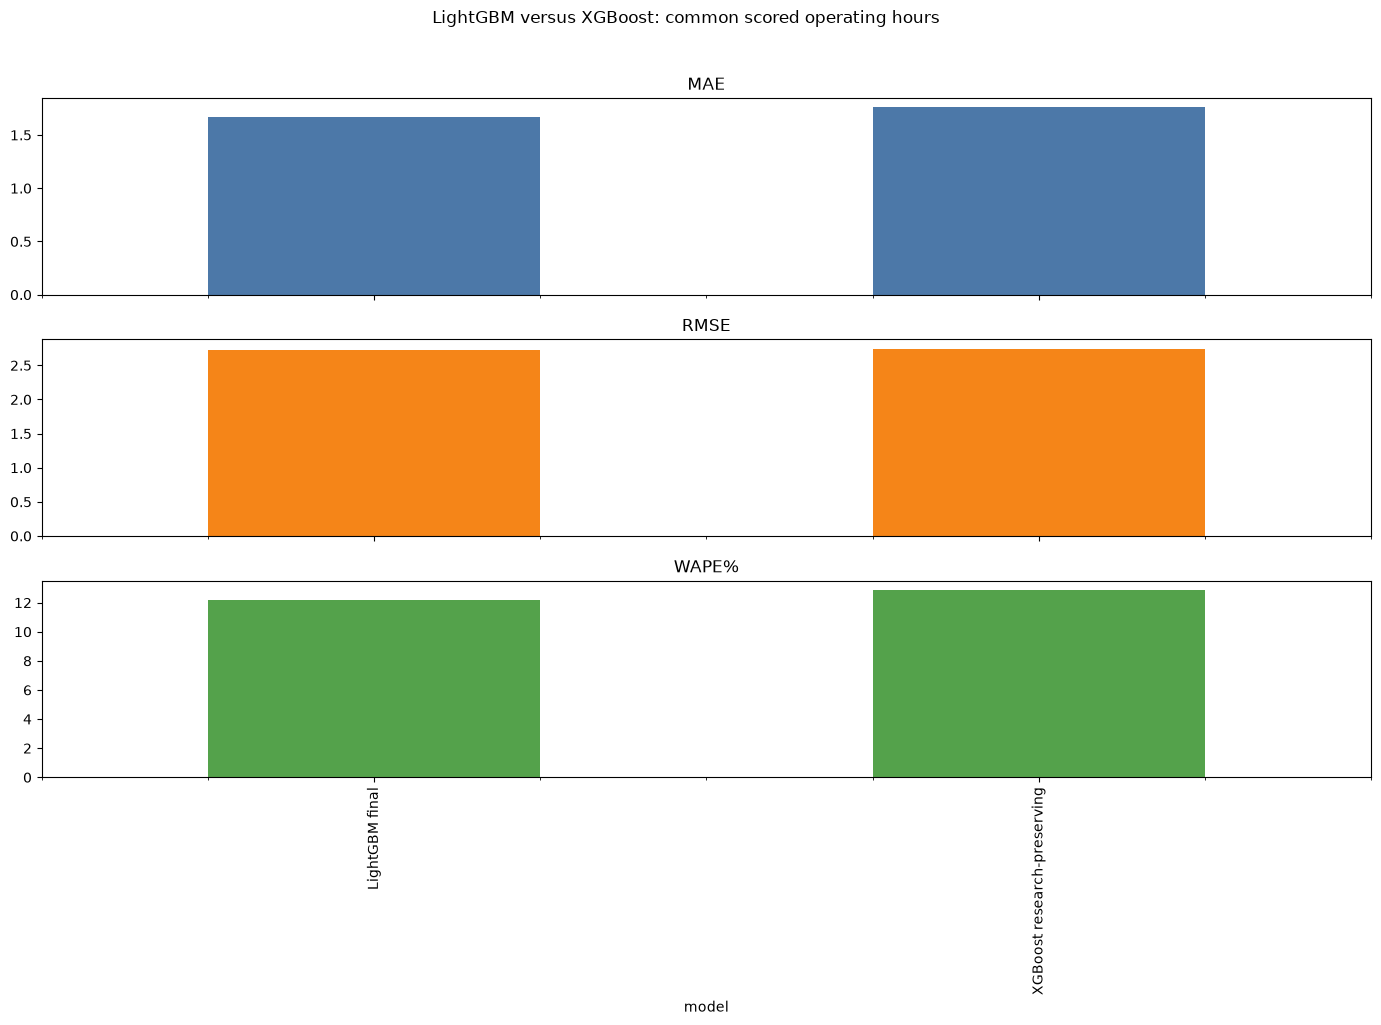

In [5]:
plot_data=operating.set_index('model')[['MAE','RMSE','WAPE%']]
ax=plot_data.plot(kind='bar',subplots=True,figsize=(14,10),layout=(3,1),legend=False,color=['#4C78A8','#F58518','#54A24B','#E45756','#72B7B2'])
plt.suptitle('LightGBM versus XGBoost: common scored operating hours',y=1.02)
plt.tight_layout()
plt.savefig(OUT_DIR/'model_comparison_operating_hours.png',dpi=180,bbox_inches='tight')
plt.show()

## 5. Per-zone comparison

In [6]:
zone_rows=[]
for zone, group in common.groupby('zone_id'):
    for model,col in pred_cols.items():
        mask=group['is_operating_hours_lgb'].eq(1)
        zone_rows.append({'zone_id':zone,'model':model,'hours':'operating hours',**metrics(group.loc[mask,'ac_load_kw_lgb'],group.loc[mask,col])})
zone_metrics=pd.DataFrame(zone_rows)
zone_metrics.to_csv(OUT_DIR/'common_zone_metrics.csv',index=False)
zone_winners=zone_metrics.loc[zone_metrics.groupby('zone_id')['WAPE%'].idxmin(),['zone_id','model','WAPE%']].sort_values('zone_id')
display(zone_winners.round(3))
print('\nNumber of zone wins by operating-hours WAPE:')
display(zone_winners['model'].value_counts().rename_axis('model').to_frame('zone_wins'))

,zone_id,model,WAPE%
0,F2_Z1,LightGBM final,7.953
2,F2_Z2,LightGBM final,18.651
5,F2_Z4,XGBoost research-preserving,10.416
7,F3_Z1,XGBoost research-preserving,9.090
8,F3_Z2,LightGBM final,9.184
10,F3_Z4,LightGBM final,12.551
13,F3_Z5,XGBoost research-preserving,14.611
14,F4_Z1,LightGBM final,8.257
16,F4_Z2,LightGBM final,11.379
18,F4_Z4,LightGBM final,12.446



Number of zone wins by operating-hours WAPE:


,zone_wins
model,
LightGBM final,16
XGBoost research-preserving,7


## 6. Comparison with existing LightGBM report

The existing LightGBM report gives the following operating-hours WAPE values on its own scored rows: **LGBM final 12.17%**, **LGBM full 12.46%**, B1 seasonal naive 16.92%, B2 average profile 19.47%, and B3 calendar + AC lags 18.12%.

The tables above recompute LightGBM final and XGBoost on the exact common scored rows. This is the fair model-to-model comparison. If a model wins on common scored WAPE but not on another metric, report WAPE as the primary operational criterion and mention the trade-off.

In [7]:
print('Saved comparison files:')
for path in sorted(OUT_DIR.iterdir()):
    print(path.name)

Saved comparison files:
common_model_metrics.csv
common_zone_metrics.csv
model_comparison_operating_hours.png
winner_summary.csv
